# Monthly exploration — base structure, 15th of each month 2016

Loads scenario data and saved results for every available date and plots:
- Electricity price profiles across the year
- Seasonal demand and PV generation per prosumer
- Device usage totals (BESS, EV, HP, grid)
- Cost and savings overview
- P2P trade volumes
- Network voltage summary

Dates with missing results (e.g. infeasible solves) are skipped automatically.


## 1  Setup

In [4]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize

ROOT = Path('.').resolve()
sys.path.insert(0, str(ROOT))

from scenarios import make_scenario_date
from metrics   import savings

plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'figure.dpi': 120,
})

STRUCTURE  = 'base'
RESULT_DIR = ROOT / 'structures' / STRUCTURE / 'results'

ALL_DATES = [
    '2016-01-15','2016-02-15','2016-03-15','2016-04-15',
    '2016-05-15','2016-06-15','2016-07-15','2016-08-15',
    '2016-09-15','2016-10-14','2016-11-15','2016-12-15',
]
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']

# Colour scheme — one colour per prosumer
P_COLORS = ['#2196F3','#FF9800','#4CAF50','#E91E63']


In [5]:
# ── Inventory: which dates have results ──────────────────────────────────────
DATES, MONTHS_OK = [], []
missing = []
for date, mon in zip(ALL_DATES, MONTHS):
    p = RESULT_DIR / date / 'centralized.json'
    if p.exists():
        DATES.append(date)
        MONTHS_OK.append(mon)
    else:
        missing.append(date)

print(f"Available: {MONTHS_OK}")
if missing:
    print(f"Missing  : {[m for d,m in zip(ALL_DATES,MONTHS) if d in missing]}")


Available: ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


In [6]:
# ── Load scenarios (profiles) and results for available dates ─────────────────
scenarios, results_c = {}, {}

for date in DATES:
    print(f"Loading {date} ...", end=' ')
    scenarios[date] = make_scenario_date(date, seed=42, resolution_h=0.5)
    raw = json.loads((RESULT_DIR / date / 'centralized.json').read_text())
    results_c[date] = raw
    print("ok")

N     = 4
T     = 48
dt    = 0.5
names = scenarios[DATES[0]]['prosumer_names']
short = [n.replace('Residential ','Res.').replace(' building','') for n in names]
print(f"\nProsumers: {names}")


Loading 2016-01-15 ... Building winter scenario (T=48, dt=0.5h, resolution=30min)...
  Prices 2016: loaded from cache
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
    ⚠ No EV activity detected — using fallback schedule
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=18.2 kW
ok
Loading 2016-02-15 ... Building winter scenario (T=48, dt=0.5h, resolution=30min)...
  Prices 2016: loaded from cache
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=14.1 kW
ok
Loading 2016-03-

## 2  Electricity price profiles across the year

/var/folders/ws/2f14f99n4gz0_l440g5w34j00000gn/T/ipykernel_35372/335748456.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap  = cm.get_cmap('plasma', len(DATES))


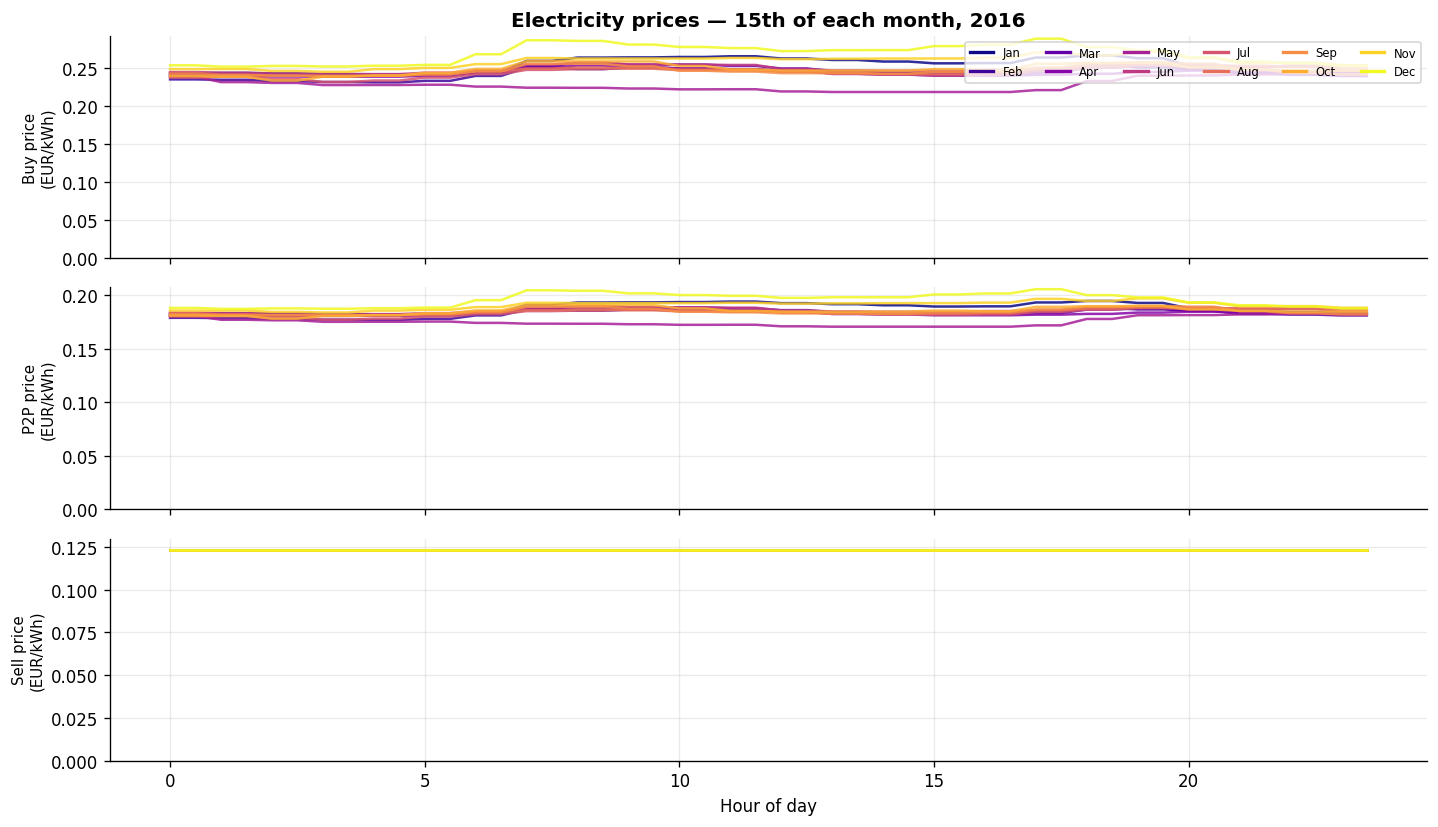

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
hours = np.arange(T) * dt

cmap  = cm.get_cmap('plasma', len(DATES))
norm  = Normalize(vmin=0, vmax=len(DATES)-1)

for ax, key, label, unit in zip(
        axes,
        ['buy_price','p2p_price','sell_price'],
        ['Buy price','P2P price','Sell price'],
        ['EUR/kWh']*3):
    for idx, (date, mon) in enumerate(zip(DATES, MONTHS_OK)):
        data = scenarios[date]
        ax.plot(hours, data[key], color=cmap(norm(idx)),
                alpha=0.85, linewidth=1.5, label=mon)
    ax.set_ylabel(f'{label}\n({unit})', fontsize=9)
    ax.set_ylim(bottom=0)

axes[-1].set_xlabel('Hour of day')
axes[0].set_title('Electricity prices — 15th of each month, 2016', fontweight='bold')

handles = [plt.Line2D([0],[0], color=cmap(norm(i)), linewidth=2, label=m)
           for i,m in enumerate(MONTHS_OK)]
axes[0].legend(handles=handles, ncol=6, fontsize=7, loc='upper right')

plt.tight_layout()
plt.savefig(ROOT / 'structures' / STRUCTURE / 'results' / 'explore_prices.pdf',
            bbox_inches='tight')
plt.show()


## 3  Seasonal demand and PV generation

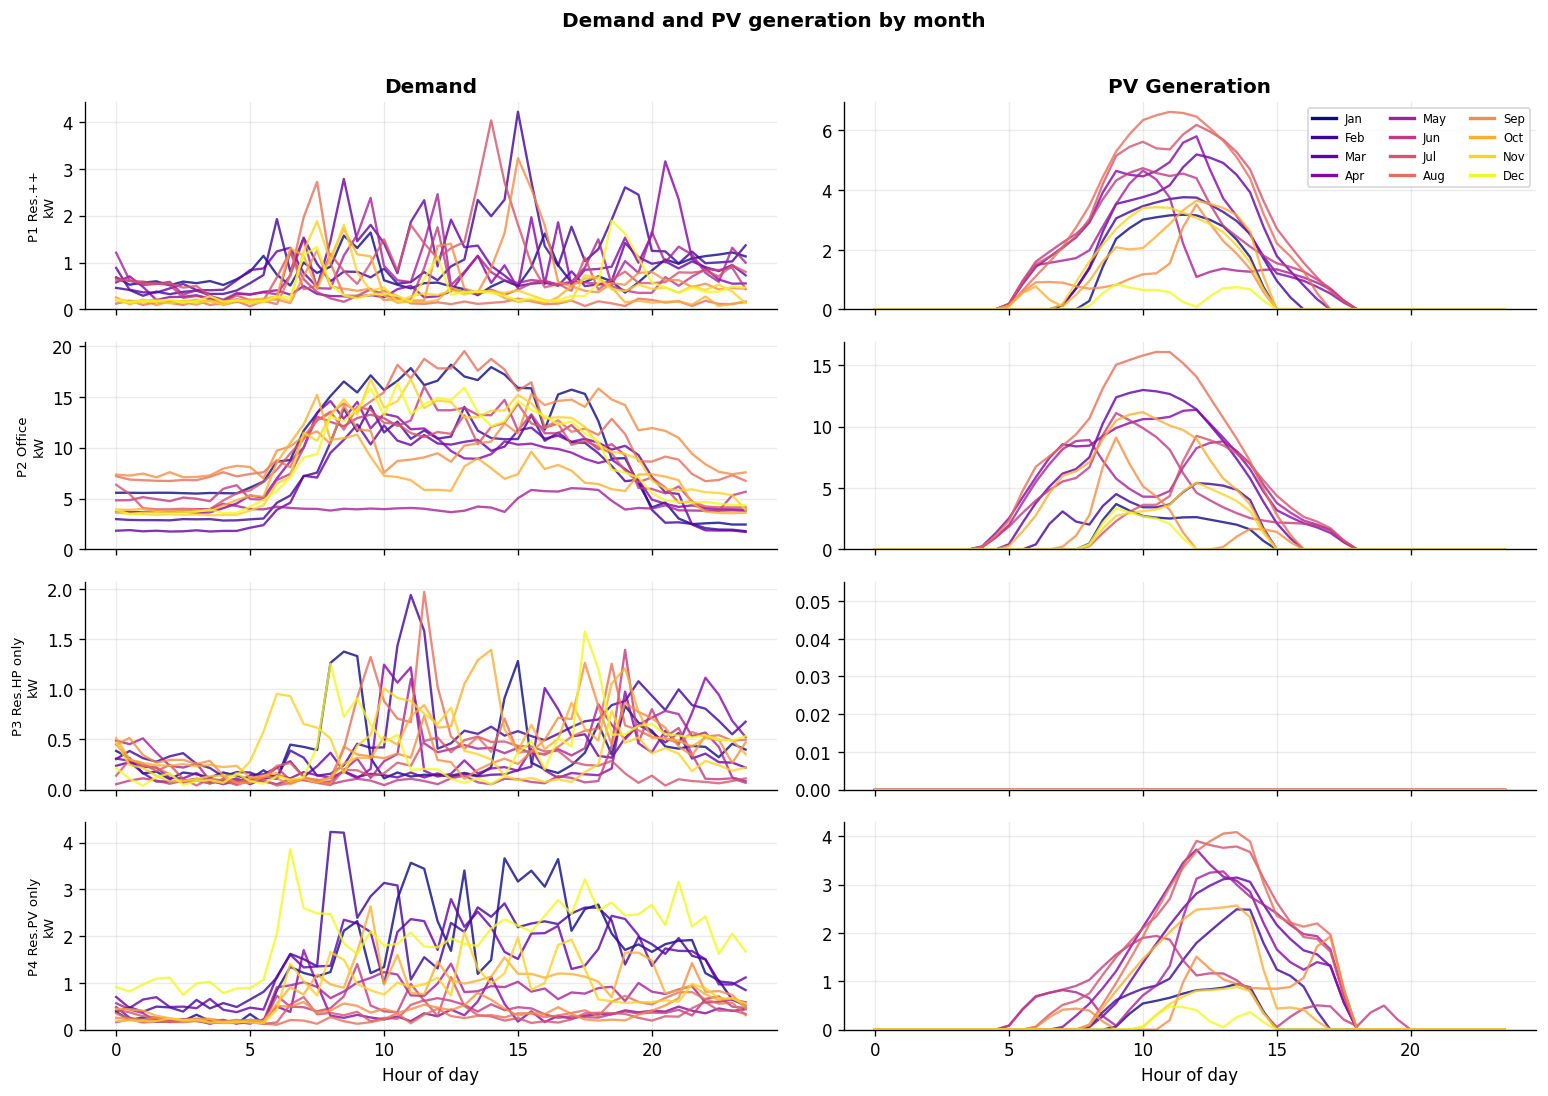

In [8]:
fig, axes = plt.subplots(N, 2, figsize=(13, 9), sharex=True)

for i in range(N):
    ax_d, ax_g = axes[i, 0], axes[i, 1]
    for idx, (date, mon) in enumerate(zip(DATES, MONTHS_OK)):
        data = scenarios[date]
        ax_d.plot(hours, data['demand'][i],     color=cmap(norm(idx)), alpha=0.8, lw=1.4)
        ax_g.plot(hours, data['generation'][i], color=cmap(norm(idx)), alpha=0.8, lw=1.4)
    ax_d.set_ylabel(f'P{i+1} {short[i]}\nkW', fontsize=8)
    if i == 0:
        ax_d.set_title('Demand', fontweight='bold')
        ax_g.set_title('PV Generation', fontweight='bold')
    ax_g.set_ylim(bottom=0)
    ax_d.set_ylim(bottom=0)

for ax in axes[-1]:
    ax.set_xlabel('Hour of day')

handles = [plt.Line2D([0],[0], color=cmap(norm(i)), lw=2, label=m)
           for i,m in enumerate(MONTHS_OK)]
axes[0,1].legend(handles=handles, ncol=3, fontsize=7, loc='upper right')

plt.suptitle('Demand and PV generation by month', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(ROOT / 'structures' / STRUCTURE / 'results' / 'explore_profiles.pdf',
            bbox_inches='tight')
plt.show()


## 4  Device usage totals per month

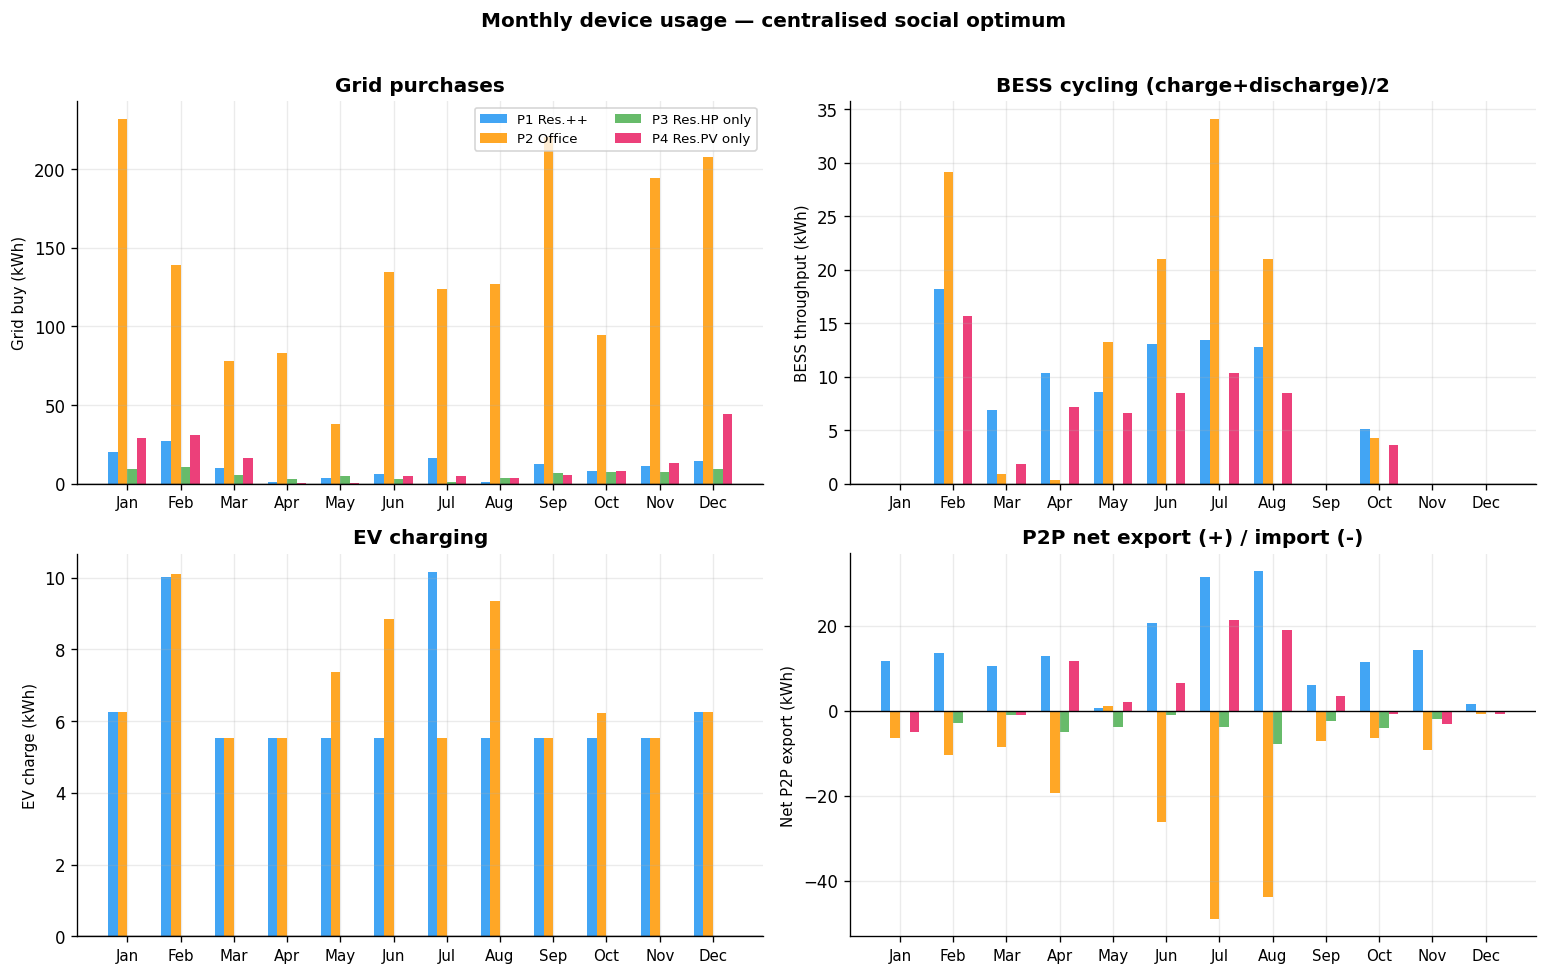

In [9]:
# Collect monthly totals from centralized results
grid_buy = np.zeros((len(DATES), N))
bess_cyc = np.zeros((len(DATES), N))   # (charge + discharge) / 2
ev_chrg  = np.zeros((len(DATES), N))
ev_disc  = np.zeros((len(DATES), N))
hp_enrg  = np.zeros((len(DATES), N))
p2p_exp  = np.zeros((len(DATES), N))   # net export (positive = sold)

for m_idx, date in enumerate(DATES):
    r = results_c[date]
    for i in range(N):
        grid_buy[m_idx, i] = np.array(r['buy'])[i].sum() * dt
        ch = np.array(r['charge'])[i]; di = np.array(r['discharge'])[i]
        bess_cyc[m_idx, i] = (ch.sum() + di.sum()) * dt / 2
        ec = np.array(r.get('ev_charge',   np.zeros((N,T))))[i]
        ed = np.array(r.get('ev_discharge', np.zeros((N,T))))[i]
        ev_chrg[m_idx, i]  = ec.sum() * dt
        ev_disc[m_idx, i]  = ed.sum() * dt
        hp = np.array(r.get('hp_power', np.zeros((N,T))))[i]
        hp_enrg[m_idx, i]  = hp.sum() * dt

        peers = [b if a==i else a
                 for a,b in scenarios[date]['edges'] if i in (a,b)]
        net = sum(r['trades'].get(f'{i}->{j}@{t}', 0.)
                  for j in peers for t in range(T))
        p2p_exp[m_idx, i] = net * dt

x  = np.arange(len(DATES))
w  = 0.18

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
panels = [
    (axes[0,0], grid_buy, 'Grid buy (kWh)',      'Grid purchases'),
    (axes[0,1], bess_cyc, 'BESS throughput (kWh)','BESS cycling (charge+discharge)/2'),
    (axes[1,0], ev_chrg,  'EV charge (kWh)',      'EV charging'),
    (axes[1,1], p2p_exp,  'Net P2P export (kWh)', 'P2P net export (+) / import (-)'),
]

for ax, data_arr, ylabel, title in panels:
    for i in range(N):
        ax.bar(x + (i - 1.5) * w, data_arr[:, i], w,
               color=P_COLORS[i], label=f'P{i+1} {short[i]}', alpha=0.85)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(MONTHS_OK, fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(title, fontweight='bold')

axes[0,0].legend(fontsize=8, ncol=2)
plt.suptitle('Monthly device usage — centralised social optimum', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(ROOT / 'structures' / STRUCTURE / 'results' / 'explore_devices.pdf',
            bbox_inches='tight')
plt.show()


## 5  Costs and savings across the year

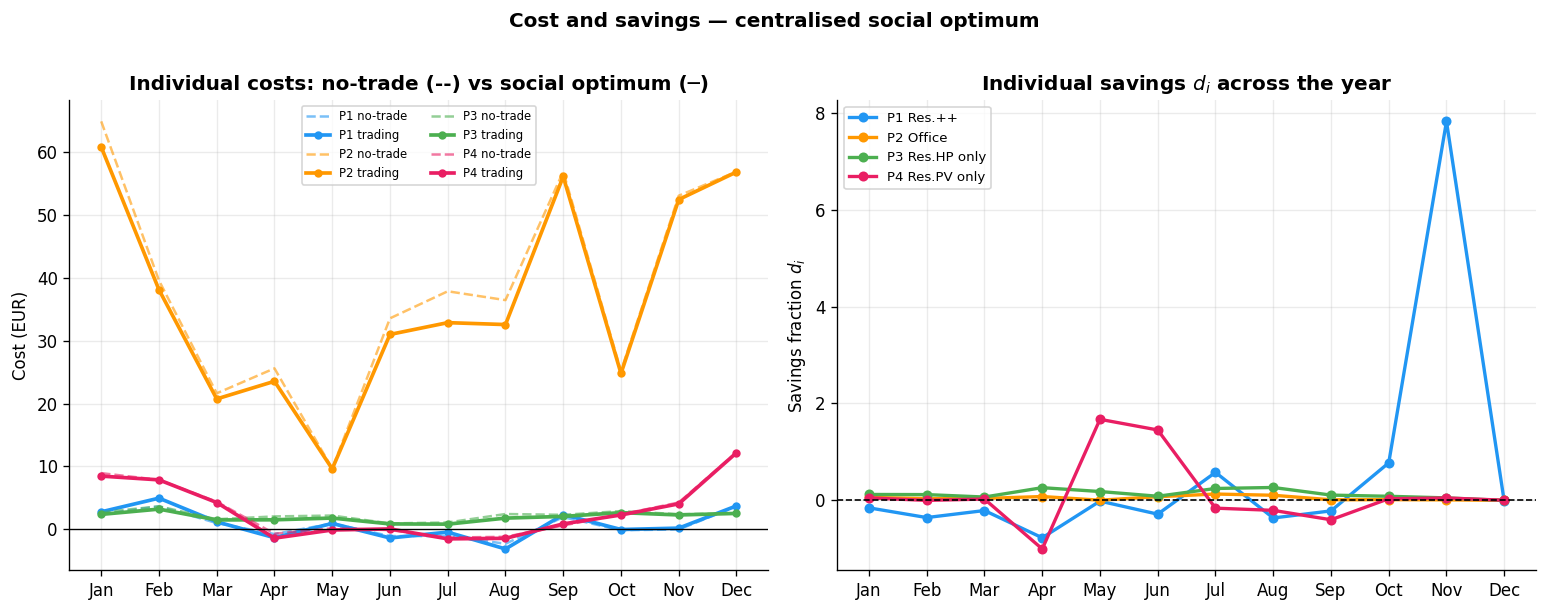

In [10]:
J_nt_all = np.zeros((len(DATES), N))
J_so_all = np.zeros((len(DATES), N))
d_all    = np.zeros((len(DATES), N))

for m_idx, date in enumerate(DATES):
    nt = json.loads((RESULT_DIR / date / 'no_trade.json').read_text())
    J_nt_all[m_idx] = nt['J_nt']
    J_so_all[m_idx] = results_c[date]['costs']
    d_all[m_idx]    = savings({'costs': J_so_all[m_idx]}, J_nt_all[m_idx])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: absolute costs — no-trade vs trade per prosumer
ax = axes[0]
for i in range(N):
    ax.plot(MONTHS_OK, J_nt_all[:, i], '--', color=P_COLORS[i],
            alpha=0.6, linewidth=1.5, label=f'P{i+1} no-trade')
    ax.plot(MONTHS_OK, J_so_all[:, i], '-',  color=P_COLORS[i],
            linewidth=2.2, marker='o', markersize=4, label=f'P{i+1} trading')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Cost (EUR)')
ax.set_title('Individual costs: no-trade (--) vs social optimum (─)', fontweight='bold')
ax.legend(fontsize=7, ncol=2)

# Right: savings d_i per month
ax2 = axes[1]
for i in range(N):
    ax2.plot(MONTHS_OK, d_all[:, i], '-o', color=P_COLORS[i],
             linewidth=2, markersize=5, label=f'P{i+1} {short[i]}')
ax2.axhline(0, color='black', linewidth=1, linestyle='--')
ax2.set_ylabel('Savings fraction $d_i$')
ax2.set_title('Individual savings $d_i$ across the year', fontweight='bold')
ax2.legend(fontsize=8)

plt.suptitle('Cost and savings — centralised social optimum', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(ROOT / 'structures' / STRUCTURE / 'results' / 'explore_costs.pdf',
            bbox_inches='tight')
plt.show()


## 6  Network voltage summary

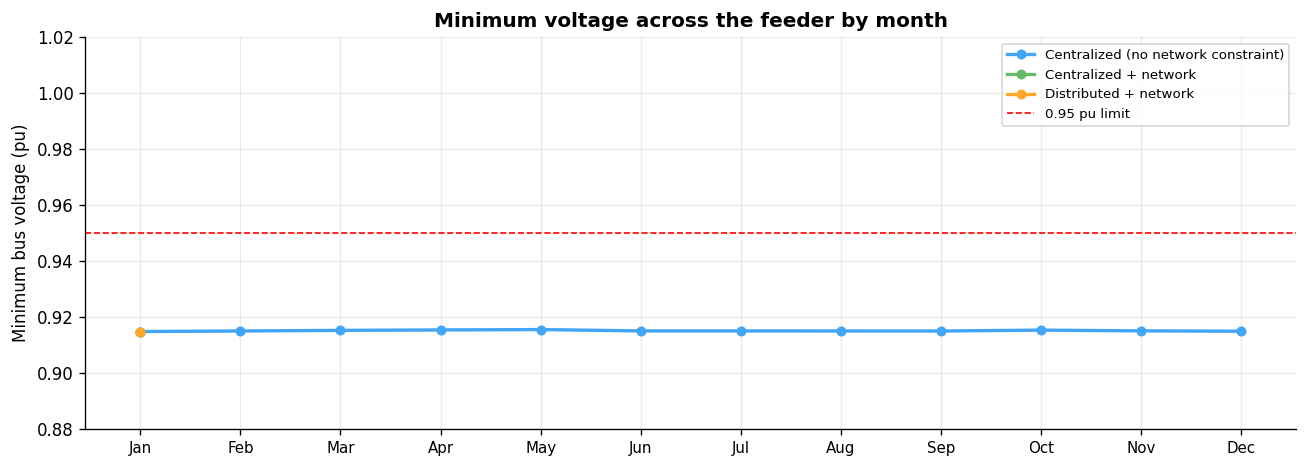

In [11]:
# Check which dates have network results and which cases
cases_with_net = ['centralized_network', 'distributed_network', 'centralized']

v_min_by_case = {c: [] for c in cases_with_net}
v_max_by_case = {c: [] for c in cases_with_net}
dates_net     = []

for date in DATES:
    row_min, row_max, found = {}, {}, False
    for case in cases_with_net:
        p = RESULT_DIR / date / f'{case}.json'
        if not p.exists():
            continue
        r   = json.loads(p.read_text())
        net = r.get('network') or {}
        vpu = net.get('voltage_pu', {})
        if vpu:
            vals = [float(v) for v in vpu.values()]
            row_min[case] = min(vals)
            row_max[case] = max(vals)
            found = True
    if found:
        dates_net.append(date)
        for case in cases_with_net:
            v_min_by_case[case].append(row_min.get(case, np.nan))
            v_max_by_case[case].append(row_max.get(case, np.nan))

if not dates_net:
    print("No network results found yet — run centralized_network / distributed_network cases first.")
else:
    months_net = [MONTHS[ALL_DATES.index(d)] for d in dates_net]
    fig, ax = plt.subplots(figsize=(11, 4))
    colors_cases = {'centralized': '#42A5F5',
                    'centralized_network': '#66BB6A',
                    'distributed_network': '#FFA726'}
    labels_cases = {'centralized':         'Centralized (no network constraint)',
                    'centralized_network':  'Centralized + network',
                    'distributed_network':  'Distributed + network'}

    x = np.arange(len(dates_net))
    for case, color in colors_cases.items():
        vmin = v_min_by_case[case]
        if all(np.isnan(v) for v in vmin):
            continue
        ax.plot(x, vmin, '-o', color=color, linewidth=2,
                markersize=5, label=labels_cases[case])

    ax.axhline(0.95, color='red', linestyle='--', linewidth=1, label='0.95 pu limit')
    ax.axhline(1.05, color='red', linestyle='--', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(months_net, fontsize=9)
    ax.set_ylabel('Minimum bus voltage (pu)')
    ax.set_title('Minimum voltage across the feeder by month', fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_ylim(0.88, 1.02)
    plt.tight_layout()
    plt.savefig(ROOT / 'structures' / STRUCTURE / 'results' / 'explore_voltages.pdf',
                bbox_inches='tight')
    plt.show()


## 7  Savings heatmap — all prosumers × all months

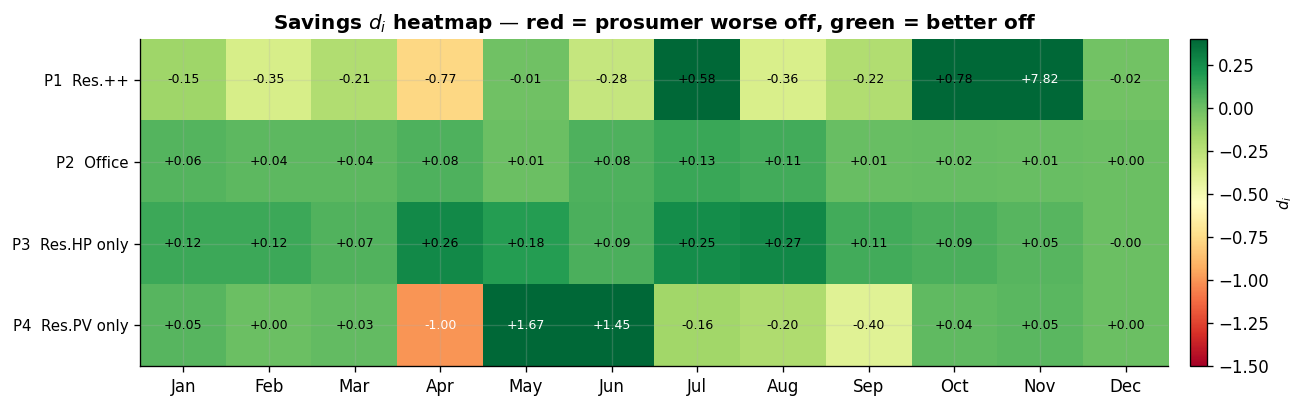


Mean savings per prosumer across available months:
  P1 Residential ++: +0.5660
  P2 Office building: +0.0486
  P3 Residential HP only: +0.1340
  P4 Residential PV only: +0.1278


In [12]:
fig, ax = plt.subplots(figsize=(11, 3.5))

im = ax.imshow(d_all.T, aspect='auto', cmap='RdYlGn',
               vmin=-1.5, vmax=0.4, interpolation='nearest')

ax.set_xticks(range(len(DATES)))
ax.set_xticklabels(MONTHS_OK, fontsize=10)
ax.set_yticks(range(N))
ax.set_yticklabels([f'P{i+1}  {short[i]}' for i in range(N)], fontsize=9)
ax.set_title('Savings $d_i$ heatmap — red = prosumer worse off, green = better off',
             fontweight='bold')

cb = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label('$d_i$', fontsize=9)

# Annotate values
for mi in range(len(DATES)):
    for pi in range(N):
        val = d_all[mi, pi]
        ax.text(mi, pi, f'{val:+.2f}', ha='center', va='center',
                fontsize=7.5, color='black' if abs(val) < 0.8 else 'white')

plt.tight_layout()
plt.savefig(ROOT / 'structures' / STRUCTURE / 'results' / 'explore_savings_heatmap.pdf',
            bbox_inches='tight')
plt.show()

print("\nMean savings per prosumer across available months:")
for i in range(N):
    print(f"  P{i+1} {names[i]}: {d_all[:,i].mean():+.4f}")
